# Solutions to notebook 15: Multibody dynamics with `sympy.physics.mechanics`

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/sympy-for-engineers/blob/main/solutions/15_multibody_mechanics.ipynb)

Worked solutions to the exercises at the end of [notebook 15](../notebooks/15_multibody_mechanics.ipynb).
Try each exercise yourself before reading its solution: the struggle is where the learning happens.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
import sympy.physics.mechanics as me
from scipy.integrate import solve_ivp
from scipy.linalg import solve_continuous_are
from sympy.calculus.euler import euler_equations

sp.init_printing(use_latex="mathjax")
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

t = me.dynamicsymbols._t          # the time symbol used by the package
m, l, g = sp.symbols("m l g", positive=True)
N = me.ReferenceFrame("N")        # fixed (inertial) frame
origin = me.Point("O")
origin.set_vel(N, 0)

## Exercise 1

A bead slides on a straight wire that rotates in a horizontal plane at constant angular
velocity $\Omega$. Using a rotating frame as in 15.1, show that its radial equation of motion
is $\ddot r = \Omega^2 r$, and find the sideways force the wire must exert on a bead of mass $m$.

The frame `W` turns with the wire, so its angle is $\Omega t$. `W.x` points along the wire and
`W.y` sideways, in the plane of rotation.

In [2]:
Omega, r_0 = sp.symbols("Omega r_0", positive=True)
r = me.dynamicsymbols("r")

W = N.orientnew("W", "Axis", [Omega * t, N.z])           # rotates with the wire
position = r * W.x
acceleration = position.dt(N).dt(N)

a_along = sp.simplify(acceleration.dot(W.x))
a_sideways = sp.simplify(acceleration.dot(W.y))
a_along, a_sideways

⎛             2                     ⎞
⎜   2        d              d       ⎟
⎜- Ω ⋅r(t) + ───(r(t)), 2⋅Ω⋅──(r(t))⎟
⎜              2            dt      ⎟
⎝            dt                     ⎠

The plane is horizontal, so gravity has no component in it, and a smooth wire can only push
sideways. Newton's law along the wire is therefore $m\,a_r = 0$, and sideways it gives the force.

In [3]:
radial_acceleration = sp.solve(a_along, r.diff(t, 2))[0]
sideways_force = m * a_sideways
radial_acceleration, sideways_force

⎛ 2             d       ⎞
⎜Ω ⋅r(t), 2⋅Ω⋅m⋅──(r(t))⎟
⎝               dt      ⎠

**Verify** in three ways. The polar formulas of 15.1 with $\dot\theta = \Omega$ and
$\ddot\theta = 0$ give the same components. Lagrange's method, which never mentions the force of
the wire, gives the same radial equation. And the power delivered by the sideways force, force
times the sideways velocity $\Omega r$, must equal the rate of change of the kinetic energy.

In [4]:
assert sp.simplify(radial_acceleration - Omega**2 * r) == 0
assert sp.simplify(sideways_force - 2 * m * Omega * r.diff(t)) == 0

bead_point = origin.locatenew("P", position)
bead_point.set_vel(N, position.dt(N))
bead = me.Particle("bead", bead_point, m)                # no potential energy in a horizontal plane
bead_equation = me.LagrangesMethod(me.Lagrangian(N, bead), [r]).form_lagranges_equations()[0]
assert sp.simplify(sp.solve(bead_equation, r.diff(t, 2))[0] - Omega**2 * r) == 0

kinetic = me.kinetic_energy(N, bead)
power_needed = kinetic.diff(t).subs(r.diff(t, 2), radial_acceleration)
assert sp.simplify(power_needed - sideways_force * Omega * r) == 0

In [5]:
# example: a bead released from rest relative to the wire at r = r_0
motion = sp.dsolve(r.diff(t, 2) - Omega**2 * r, r, ics={r.subs(t, 0): r_0, r.diff(t).subs(t, 0): 0}).rhs
assert sp.simplify((motion - r_0 * sp.cosh(Omega * t)).rewrite(sp.exp)) == 0
force_in_time = sp.simplify(sideways_force.subs(r, motion).doit().rewrite(sp.sinh))
force_in_time

   2               
2⋅Ω ⋅m⋅r₀⋅sinh(Ω⋅t)

**Answer.** The acceleration along the wire is $\ddot r - \Omega^2 r$, and no force acts in that
direction, so $\ddot r = \Omega^2 r$. The wire must supply the sideways (Coriolis) force
$2m\Omega\,\dot r$, in the direction of rotation while the bead moves outwards. It also carries
the weight $mg$ vertically. A bead released at $r_0$ moves out as $r = r_0\cosh\Omega t$, and the
force on it grows as $2m\Omega^2 r_0\sinh\Omega t$. This force does work on the bead, which is
where its growing kinetic energy comes from.

## Exercise 2

Derive the double pendulum of notebook 12 with `LagrangesMethod`, using one frame per rod,
and check that the angular accelerations agree with those of notebook 12 for equal masses
and lengths at one numerical state.

Follow the five steps of 15.2. Both angles are measured from the vertical, as in notebook 12, so
each rod frame is obtained by rotating the fixed frame.

In [6]:
m1, m2, l1, l2 = sp.symbols("m_1 m_2 l_1 l_2", positive=True)
q1, q2 = me.dynamicsymbols("q_1 q_2")

rod1 = N.orientnew("B_1", "Axis", [q1, N.z])             # 1. one frame per rod
rod2 = N.orientnew("B_2", "Axis", [q2, N.z])
P1 = origin.locatenew("P_1", -l1 * rod1.y)               # 2. the two masses
P2 = P1.locatenew("P_2", -l2 * rod2.y)
P1.v2pt_theory(origin, N, rod1)                          # 3. velocities, each relative to the rod's upper end
P2.v2pt_theory(P1, N, rod2)

upper = me.Particle("upper", P1, m1)                     # 4. bodies and potential energies
lower = me.Particle("lower", P2, m2)
upper.potential_energy = m1 * g * P1.pos_from(origin).dot(N.y)
lower.potential_energy = m2 * g * P2.pos_from(origin).dot(N.y)

double = me.LagrangesMethod(me.Lagrangian(N, upper, lower), [q1, q2])     # 5. Lagrange's equations
sp.simplify(double.form_lagranges_equations())

⎡   ⎛                                           2                  2           ↪
⎢   ⎜                                          d                  d            ↪
⎢l₁⋅⎜g⋅m₁⋅sin(q₁(t)) + g⋅m₂⋅sin(q₁(t)) + l₁⋅m₁⋅───(q₁(t)) + l₁⋅m₂⋅───(q₁(t)) + ↪
⎢   ⎜                                            2                  2          ↪
⎢   ⎝                                          dt                 dt           ↪
⎢                                                                              ↪
⎢                             ⎛                                                ↪
⎢                             ⎜                                     ⎛d         ↪
⎢                       l₂⋅m₂⋅⎜g⋅sin(q₂(t)) - l₁⋅sin(q₁(t) - q₂(t))⋅⎜──(q₁(t)) ↪
⎢                             ⎜                                     ⎝dt        ↪
⎣                             ⎝                                                ↪

↪                                      2                             2         ↪
↪                          

In [7]:
mech_rates = sp.simplify(double.rhs())                   # (q1', q2', q1'', q2'')
mech_rates[2]

                                                                               ↪
                                                                               ↪
2⋅g⋅m₁⋅sin(q₁(t)) + g⋅m₂⋅sin(q₁(t) - 2⋅q₂(t)) + g⋅m₂⋅sin(q₁(t)) + l₁⋅m₂⋅sin(2⋅ ↪
                                                                               ↪
────────────────────────────────────────────────────────────────────────────── ↪
                                                     l₁⋅(-2⋅m₁ + m₂⋅cos(2⋅q₁(t ↪

↪                             2                                         2
↪                  ⎛d        ⎞                               ⎛d        ⎞ 
↪ q₁(t) - 2⋅q₂(t))⋅⎜──(q₁(t))⎟  + 2⋅l₂⋅m₂⋅sin(q₁(t) - q₂(t))⋅⎜──(q₂(t))⎟ 
↪                  ⎝dt       ⎠                               ⎝dt       ⎠ 
↪ ───────────────────────────────────────────────────────────────────────
↪ ) - 2⋅q₂(t)) - m₂)                                                     

For the comparison, repeat the derivation of notebook 12: Cartesian positions, energies and
`euler_equations`.

In [8]:
th1 = sp.Function("theta_1")(t)
th2 = sp.Function("theta_2")(t)

x1, y1 = l1 * sp.sin(th1), -l1 * sp.cos(th1)
x2, y2 = x1 + l2 * sp.sin(th2), y1 - l2 * sp.cos(th2)
T = sp.simplify(m1 * (x1.diff(t) ** 2 + y1.diff(t) ** 2) / 2 + m2 * (x2.diff(t) ** 2 + y2.diff(t) ** 2) / 2)
V = m1 * g * y1 + m2 * g * y2

accelerations = sp.solve(euler_equations(T - V, [th1, th2], t), [th1.diff(t, 2), th2.diff(t, 2)], dict=True)[0]
alpha1 = sp.simplify(accelerations[th1.diff(t, 2)])
alpha2 = sp.simplify(accelerations[th2.diff(t, 2)])

In [9]:
# both results as functions of plain symbols (derivatives are substituted first)
a1, a2, w1, w2 = sp.symbols("a_1 a_2 omega_1 omega_2")
from_mechanics = [expr.subs({q1.diff(t): w1, q2.diff(t): w2}).subs({q1: a1, q2: a2}) for expr in mech_rates[2:]]
from_notebook_12 = [expr.subs({th1.diff(t): w1, th2.diff(t): w2}).subs({th1: a1, th2: a2}) for expr in (alpha1, alpha2)]

# equal masses and lengths, at one state: 120° and -20°, with both rods moving
params = {m1: 1.0, m2: 1.0, l1: 1.0, l2: 1.0, g: 9.81}
state = {a1: np.radians(120), a2: np.radians(-20), w1: 0.7, w2: -1.3}
values_mechanics = [float(expr.subs(params).subs(state)) for expr in from_mechanics]
values_notebook_12 = [float(expr.subs(params).subs(state)) for expr in from_notebook_12]
print("LagrangesMethod:", np.round(values_mechanics, 6), "rad/s²")
print("notebook 12:    ", np.round(values_notebook_12, 6), "rad/s²")
assert np.allclose(values_mechanics, values_notebook_12, rtol=1e-12)

LagrangesMethod: [-10.802764  -4.605214] rad/s²
notebook 12:     [-10.802764  -4.605214] rad/s²


In [10]:
# stronger: the two derivations agree symbolically, for any masses, lengths and state
assert all(sp.simplify(one - other) == 0 for one, other in zip(from_mechanics, from_notebook_12))
# and the kinetic energy built from the frames equals the Cartesian one
T_frames = me.kinetic_energy(N, upper, lower).subs({q1.diff(t): th1.diff(t), q2.diff(t): th2.diff(t)}).subs({q1: th1, q2: th2})
assert sp.simplify(T_frames - T) == 0

**Answer.** With one frame per rod, `v2pt_theory` supplies both velocities and
`LagrangesMethod` returns the same two coupled equations as notebook 12. For equal masses and
lengths (1 kg, 1 m) at $\theta_1 = 120°$, $\theta_2 = -20°$, $\dot\theta_1 = 0.7$ rad/s and
$\dot\theta_2 = -1.3$ rad/s, both derivations give $\ddot\theta_1 = -10.8028$ rad/s² and
$\ddot\theta_2 = -4.6052$ rad/s². The agreement is in fact exact for all parameter values.

## Exercise 3

Add viscous friction $-b\dot x$ on the cart and $-c\dot\theta$ at the hinge in 15.3 (as a
force and a torque in `forcelist`). How do the entries of $\mathbf{A}$ change, and is the
upright position still unstable?

Rebuild the model of 15.3. The friction force acts at the cart's point. The hinge torque acts
on the rod's frame and opposes its angular velocity, which the frame object provides
($-\dot\theta$ about `N.z`, because leaning to the right is positive $\theta$). The opposite
torque acts on the cart, which does not rotate, so it does no work and is left out.

In [11]:
M = sp.symbols("M", positive=True)
b, c = sp.symbols("b c", nonnegative=True)
x, theta = me.dynamicsymbols("x theta")
F = me.dynamicsymbols("F")

rod = N.orientnew("R", "Axis", [-theta, N.z])            # leaning to the right is positive θ
cart_point = origin.locatenew("C", x * N.x)
cart_point.set_vel(N, x.diff(t) * N.x)
tip = cart_point.locatenew("T", l * rod.y)
tip.v2pt_theory(cart_point, N, rod)

cart = me.Particle("cart", cart_point, M)
mass = me.Particle("mass", tip, m)
cart.potential_energy = 0
mass.potential_energy = m * g * tip.pos_from(origin).dot(N.y)

with_friction = me.LagrangesMethod(
    me.Lagrangian(N, cart, mass), [x, theta],
    forcelist=[(cart_point, (F - b * x.diff(t)) * N.x),     # push and friction on the cart
               (rod, -c * rod.ang_vel_in(N))],              # friction torque on the rod
    frame=N,
)
equations = sp.simplify(with_friction.form_lagranges_equations())
equations

⎡   2                         ⎛                        2                2      ↪
⎢  d             d            ⎜              ⎛d       ⎞                d       ↪
⎢M⋅───(x(t)) + b⋅──(x(t)) + m⋅⎜- l⋅sin(θ(t))⋅⎜──(θ(t))⎟  + l⋅cos(θ(t))⋅───(θ(t ↪
⎢    2           dt           ⎜              ⎝dt      ⎠                  2     ↪
⎢  dt                         ⎝                                        dt      ↪
⎢                                                                              ↪
⎢                                                   2                          ↪
⎢                d                             2   d                         d ↪
⎢              c⋅──(θ(t)) - g⋅l⋅m⋅sin(θ(t)) + l ⋅m⋅───(θ(t)) + l⋅m⋅cos(θ(t))⋅─ ↪
⎢                dt                                  2                         ↪
⎣                                                  dt                        d ↪

↪       2       ⎞       ⎤
↪      d        ⎟       ⎥
↪ )) + ───(x(t))⎟ - F(t)⎥
↪        2      ⎟       ⎥
↪   

In [12]:
# verify against the textbook equations of 15.3 with the two friction terms added by hand
x_dd, th_dd, x_d, th_d = x.diff(t, 2), theta.diff(t, 2), x.diff(t), theta.diff(t)
by_hand = sp.Matrix([
    (M + m) * x_dd + m * l * (th_dd * sp.cos(theta) - th_d**2 * sp.sin(theta)) - F + b * x_d,
    m * l * (l * th_dd + x_dd * sp.cos(theta) - g * sp.sin(theta)) + c * th_d,
])
assert sp.simplify(equations - by_hand) == sp.zeros(2, 1)

# verify the signs with an energy balance: dE/dt = F x' - b x'² - c θ'², so friction only removes energy
friction_rates = sp.simplify(with_friction.rhs())
total_energy = me.kinetic_energy(N, cart, mass) + me.potential_energy(cart, mass)
energy_rate = total_energy.diff(t).subs({x_dd: friction_rates[2], th_dd: friction_rates[3]})
assert sp.simplify(energy_rate - (F * x_d - b * x_d**2 - c * th_d**2)) == 0

In [13]:
upright = {x: 0, theta: 0, x_d: 0, th_d: 0, F: 0}
linearizer = with_friction.to_linearizer(q_ind=[x, theta], qd_ind=[x_d, th_d])
A_friction, B_friction = linearizer.linearize(A_and_B=True, op_point=upright)
A_friction, B_friction = sp.simplify(A_friction), sp.simplify(B_friction)
A_friction

⎡0      0       1        0     ⎤
⎢                              ⎥
⎢0      0       0        1     ⎥
⎢                              ⎥
⎢     -g⋅m     -b        c     ⎥
⎢0    ─────    ───      ───    ⎥
⎢       M       M       M⋅l    ⎥
⎢                              ⎥
⎢   g⋅(M + m)   b   -c⋅(M + m) ⎥
⎢0  ─────────  ───  ───────────⎥
⎢      M⋅l     M⋅l       2     ⎥
⎣                     M⋅l ⋅m   ⎦

In [14]:
# the change from the frictionless matrix of 15.5
A_sym, B_sym = A_friction.subs({b: 0, c: 0}), B_friction
A_lesson = sp.Matrix([[0, 0, 1, 0], [0, 0, 0, 1], [0, -m * g / M, 0, 0], [0, (M + m) * g / (M * l), 0, 0]])
assert sp.simplify(A_sym - A_lesson) == sp.zeros(4, 4)

change = sp.simplify(A_friction - A_sym)
expected = sp.zeros(4, 4)
expected[2, 2], expected[2, 3] = -b / M, c / (M * l)
expected[3, 2], expected[3, 3] = b / (M * l), -c * (M + m) / (M * m * l**2)
assert sp.simplify(change - expected) == sp.zeros(4, 4)
change

⎡0  0   0        0     ⎤
⎢                      ⎥
⎢0  0   0        0     ⎥
⎢                      ⎥
⎢      -b        c     ⎥
⎢0  0  ───      ───    ⎥
⎢       M       M⋅l    ⎥
⎢                      ⎥
⎢       b   -c⋅(M + m) ⎥
⎢0  0  ───  ───────────⎥
⎢      M⋅l       2     ⎥
⎣             M⋅l ⋅m   ⎦

**Stability.** The characteristic polynomial has a factor $s$ (the cart position does not
appear in the equations) times a cubic.

In [15]:
s = sp.symbols("s")
cubic = sp.collect(sp.expand(sp.cancel(A_friction.charpoly(s).as_expr() / s)), s)
cubic

 3    2 ⎛ c     b    c  ⎞     ⎛  g    b⋅c     g⋅m⎞   b⋅g
s  + s ⋅⎜──── + ─ + ────⎟ + s⋅⎜- ─ + ────── - ───⎟ - ───
        ⎜ 2     M      2⎟     ⎜  l      2     M⋅l⎟   M⋅l
        ⎝l ⋅m       M⋅l ⎠     ⎝      M⋅l ⋅m      ⎠      

The cubic tends to $+\infty$ for large $s$ and its value at $s = 0$ is $-bg/(Ml)$, which is
negative. It must cross zero at some positive $s$: there is always a positive eigenvalue. If
$b = 0$ the cubic is $s$ times a quadratic whose constant term $-(M+m)g/(Ml)$ is negative, with
the same conclusion.

In [16]:
assert sp.simplify(cubic.subs(s, 0) + b * g / (M * l)) == 0
quadratic = sp.cancel(cubic.subs(b, 0) / s)
assert sp.simplify(quadratic.subs(s, 0) + (M + m) * g / (M * l)) == 0

numbers = {M: 1.0, m: 0.2, l: 0.5, g: 9.81}                 # kg, kg, m, m/s², as in 15.6
print("   b (N·s/m)   c (N·m·s)   eigenvalues (1/s)")
for b_value, c_value in ((0, 0), (0.5, 0.02), (5, 0.5), (100, 10)):
    eigenvalues = np.linalg.eigvals(np.array(A_friction.subs(numbers).subs({b: b_value, c: c_value}), dtype=float))
    eigenvalues = np.sort(eigenvalues.real)
    print(f"{b_value:10g} {c_value:11g}    ", np.round(eigenvalues, 3))
    assert np.abs(eigenvalues).min() < 1e-9 and eigenvalues.max() > 0       # one zero, one positive
assert abs(eigenvalues.max() - 0.2 * 9.81 * 0.5 / 10) < 1e-3                # heavy friction: rate → mgl/c

   b (N·s/m)   c (N·m·s)   eigenvalues (1/s)
         0           0     [-4.852  0.     0.     4.852]
       0.5        0.02     [-5.146 -0.416  0.     4.582]
         5         0.5     [-14.757  -3.933   0.      1.69 ]
       100          10     [-2.64425e+02 -7.56730e+01  0.00000e+00  9.80000e-02]


**Answer.** The position columns of $\mathbf{A}$ are unchanged. Friction fills the lower right
block, which was zero:

$$\frac{\partial(\ddot x, \ddot\theta)}{\partial(\dot x, \dot\theta)} =
\begin{pmatrix} -\dfrac{b}{M} & \dfrac{c}{Ml} \\[2mm] \dfrac{b}{Ml} & -\dfrac{(M+m)\,c}{Mml^2} \end{pmatrix}.$$

$\mathbf{B}$ is unchanged. The upright position is still unstable for every $b$ and $c$: the
characteristic cubic is negative at $s = 0$, so it always has a positive root. With the numbers
of 15.6, $b = 0.5$ N·s/m and $c = 0.02$ N·m·s lower the unstable eigenvalue from 4.85 to
4.58 s⁻¹. Friction slows the fall but cannot stop it, because it produces no force at rest. Even
with very heavy friction the rod still creeps over, at the rate $mgl/c$.

## Exercise 4

A uniform rod of length $L$ is pivoted at a distance $d$ from its centre. Find the period of
small swings as a function of $d$, and the value of $d$ that makes it shortest.
(Answer: $d = L/\sqrt{12}$.)

The model of 15.7 with one change: the centre of mass is at $-d\,\mathbf{s}_y$ from the hinge
instead of $-\tfrac{L}{2}\mathbf{s}_y$.

In [17]:
L, d = sp.symbols("L d", positive=True)
phi = me.dynamicsymbols("phi")

body_frame = N.orientnew("S", "Axis", [phi, N.z])
hinge = me.Point("H")
hinge.set_vel(N, 0)
centre = hinge.locatenew("G", -d * body_frame.y)
centre.v2pt_theory(hinge, N, body_frame)

central_inertia = me.inertia(body_frame, 0, 0, m * L**2 / 12)
rod_body = me.RigidBody("rod", centre, body_frame, m, (central_inertia, centre))
rod_body.potential_energy = m * g * centre.pos_from(hinge).dot(N.y)

rod_equation = me.LagrangesMethod(me.Lagrangian(N, rod_body), [phi]).form_lagranges_equations()[0]
phi_ddot = sp.simplify(sp.solve(rod_equation, phi.diff(t, 2))[0])
phi_ddot

-12⋅d⋅g⋅sin(φ(t)) 
──────────────────
     2       2    
    L  + 12⋅d     

In [18]:
# small swings: φ'' = -ω² φ, with ω² the slope of -φ'' at φ = 0 (notebook 9)
phi_s = sp.symbols("phi_s")
omega_squared = -sp.diff(phi_ddot.subs(phi, phi_s), phi_s).subs(phi_s, 0)
period = 2 * sp.pi / sp.sqrt(omega_squared)
sp.simplify(period)

     ______________
    ╱    2       2 
π⋅╲╱  3⋅L  + 36⋅d  
───────────────────
      3⋅√d⋅√g      

In [19]:
d_best = sp.solve(sp.diff(period, d), d)
period_min = sp.simplify(period.subs(d, d_best[0]))
d_best, period_min

⎛           3/4     ⎞
⎜⎡√3⋅L⎤  2⋅3   ⋅π⋅√L⎟
⎜⎢────⎥, ───────────⎟
⎝⎣ 6  ⎦     3⋅√g    ⎠

In [20]:
# verify: the hand formula from the parallel-axis theorem, I = m L²/12 + m d², torque = -m g d sin φ
assert sp.simplify(phi_ddot + m * g * d * sp.sin(phi) / (m * L**2 / 12 + m * d**2)) == 0
assert sp.simplify(period - 2 * sp.pi * sp.sqrt((L**2 / 12 + d**2) / (g * d))) == 0
# pivot at the end, d = L/2: the result of 15.7
assert sp.simplify(period.subs(d, L / 2) - 2 * sp.pi * sp.sqrt(2 * L / (3 * g))) == 0
# the stationary point is the stated one, it is the only one, and it is a minimum
assert len(d_best) == 1 and sp.simplify(d_best[0] - L / sp.sqrt(12)) == 0
assert sp.simplify(sp.diff(period, d, 2).subs(d, d_best[0])).is_positive
assert sp.limit(period, d, 0, "+") == sp.oo              # pivot at the centre: no restoring torque
assert sp.simplify(period_min - 2 * sp.pi * sp.sqrt(L / (sp.sqrt(3) * g))) == 0

L = 1 m: period 1.638 s with the pivot at the end, 1.524 s at d = 0.289 m


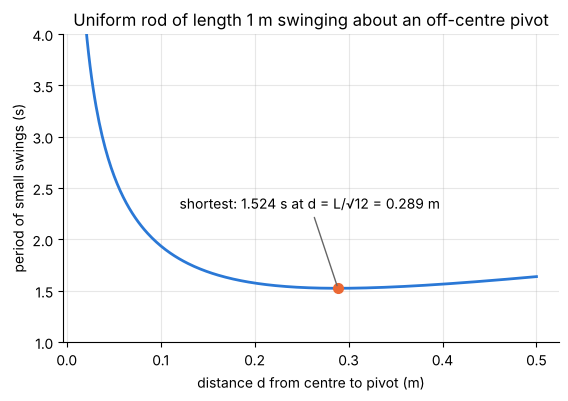

In [21]:
one_metre = {L: 1, g: 9.81}
period_fun = sp.lambdify(d, period.subs(one_metre), "numpy")
d_values = np.linspace(0.02, 0.5, 300)
d_star, T_star = float(d_best[0].subs(one_metre)), float(period_min.subs(one_metre))

fig, ax = plt.subplots()
ax.plot(d_values, period_fun(d_values))
ax.plot(d_star, T_star, "o", color="#eb6834", ms=7)
ax.annotate(f"shortest: {T_star:.3f} s at d = L/√12 = {d_star:.3f} m", xy=(d_star, T_star), xytext=(0.12, 2.3),
            arrowprops=dict(arrowstyle="-", color="0.4"))
ax.set(xlabel="distance d from centre to pivot (m)", ylabel="period of small swings (s)", ylim=(1, 4),
       title="Uniform rod of length 1 m swinging about an off-centre pivot")
print(f"L = 1 m: period {period_fun(0.5):.3f} s with the pivot at the end, {T_star:.3f} s at d = {d_star:.3f} m")
assert period_fun(d_values).min() >= T_star - 1e-12

**Answer.** The equation of motion is $\left(\tfrac{1}{12}L^2 + d^2\right)\ddot\phi = -g\,d\sin\phi$,
so the period of small swings is

$$T(d) = 2\pi\sqrt{\frac{L^2/12 + d^2}{g\,d}} .$$

It is shortest for $d = L/\sqrt{12} \approx 0.289\,L$, where the pivot distance equals the
radius of gyration about the centre, and then $T_{min} = 2\pi\sqrt{L/(\sqrt3\,g)}$. For a 1 m rod
that is 1.524 s, against 1.638 s with the pivot at the end. The period grows without limit as
the pivot approaches the centre, because the restoring torque vanishes.

## Exercise 5

With the controller of 15.6, find by simulation the largest initial tilt from which the
pendulum is still recovered. Then limit the available force to $\pm 20$ N and find it again.
(Count a run as recovered if the rod never reaches the horizontal and is upright after 10 s.)

The model is the cart and pendulum of exercise 3 without friction. Rebuild the controller of
15.6 from it.

In [22]:
A_num = np.array(A_sym.subs(numbers), dtype=float)
B_num = np.array(B_sym.subs(numbers), dtype=float)

Q_weight = np.diag([1.0, 10.0, 0.0, 0.0])
R_weight = np.array([[0.1]])
P = solve_continuous_are(A_num, B_num, Q_weight, R_weight)
K = np.linalg.solve(R_weight, B_num.T @ P)
assert np.allclose(K, [[-3.16, -40.50, -4.30, -8.39]], atol=0.005)          # the gain printed in 15.6
print("gain K =", np.round(K, 2))

state_symbols = sp.symbols("x_s theta_s v_s omega_s")
F_symbol = sp.symbols("F_s")
to_symbols = {x_d: state_symbols[2], th_d: state_symbols[3],
              x: state_symbols[0], theta: state_symbols[1], F: F_symbol}       # derivatives first
state_rates = friction_rates.subs({b: 0, c: 0})
rates = sp.lambdify((*state_symbols, F_symbol), list(state_rates.subs(to_symbols).subs(numbers)), "numpy")

gain K = [[ -3.16 -40.5   -4.3   -8.39]]


A run counts as **recovered** if the rod never reaches the horizontal and is upright (within
$10^{-3}$ rad) after 10 s. An event stops the integration as soon as $|\theta| = 90°$. The force
limit is applied with `np.clip`, and no limit is `F_max = np.inf`. All runs start from rest
with the cart at $x = 0$.

In [23]:
def simulate(tilt_deg, F_max=np.inf, t_end=10.0, method="RK45"):
    force = lambda y: float(np.clip(-(K @ y)[0], -F_max, F_max))
    fallen = lambda _, y: abs(y[1]) - np.pi / 2
    fallen.terminal = True
    sol = solve_ivp(lambda _, y: rates(*y, force(y)), [0, t_end], [0.0, np.radians(tilt_deg), 0.0, 0.0],
                    events=fallen, method=method, t_eval=np.linspace(0, t_end, 2001), rtol=1e-9, atol=1e-9)
    recovered = sol.status == 0 and abs(sol.y[1, -1]) < 1e-3
    return recovered, sol.t, sol.y, np.array([force(y) for y in sol.y.T])

def recovers(tilt_deg, F_max=np.inf, method="RK45"):
    return simulate(tilt_deg, F_max, method=method)[0]

assert recovers(15) and recovers(15, F_max=20)           # the case of 15.6

In [24]:
# a coarse scan first: is there a single limit, with recovery below it and failure above?
scan = np.arange(1, 90)
for F_max in (np.inf, 20.0):
    outcome = np.array([recovers(tilt, F_max) for tilt in scan])
    last_good = scan[outcome].max()
    assert outcome[scan <= last_good].all() and not outcome[scan > last_good].any()
    print(f"force limit {F_max:4g} N: recovered from every tilt up to {last_good}°, from none above")

force limit  inf N: recovered from every tilt up to 62°, from none above


force limit   20 N: recovered from every tilt up to 52°, from none above


In [25]:
# then bisection between a tilt that is recovered and one that is not
def largest_tilt(F_max, low=10.0, high=89.0):
    while high - low > 0.01:
        middle = (low + high) / 2
        low, high = (middle, high) if recovers(middle, F_max) else (low, middle)
    return low, high

limits = {F_max: largest_tilt(F_max) for F_max in (np.inf, 20.0)}
for F_max, (low, high) in limits.items():
    _, _, y_low, force_low = simulate(low, F_max)
    print(f"force limit {F_max:4g} N: largest tilt {low:.2f}°   "
          f"(peak force {np.abs(force_low).max():.1f} N, cart travels up to {np.abs(y_low[0]).max():.2f} m)")

force limit  inf N: largest tilt 62.68°   (peak force 44.5 N, cart travels up to 3.79 m)
force limit   20 N: largest tilt 52.43°   (peak force 20.0 N, cart travels up to 3.52 m)


**Verify.** The limit should not depend on the integrator, so repeat both sides of each bracket
with two other methods, one of them implicit. For the limited force there is also a simple
bound. From the equations of 15.3, a rod at rest at angle $\theta$ has
$\ddot\theta \propto (M+m)\,g\sin\theta - F\cos\theta$, so when
$\tan\theta > F_{max}/[(M+m)g]$ even the full force cannot start it moving back. The limit found
by simulation must lie below that angle.

In [26]:
for F_max, (low, high) in limits.items():
    for method in ("DOP853", "Radau"):
        assert recovers(low, F_max, method) and not recovers(high, F_max, method)

at_rest = {x: 0, x_d: 0, th_d: 0}
numerator = sp.simplify(state_rates[3].subs(at_rest) * (M + m * sp.sin(theta) ** 2) * l)
assert sp.simplify(numerator - ((M + m) * g * sp.sin(theta) - F * sp.cos(theta))) == 0

static_bound = np.degrees(np.arctan(20.0 / ((1.0 + 0.2) * 9.81)))
print(f"static bound for ±20 N: {static_bound:.1f}°")
assert limits[20.0][0] < static_bound and limits[20.0][0] < limits[np.inf][0]

static bound for ±20 N: 59.5°


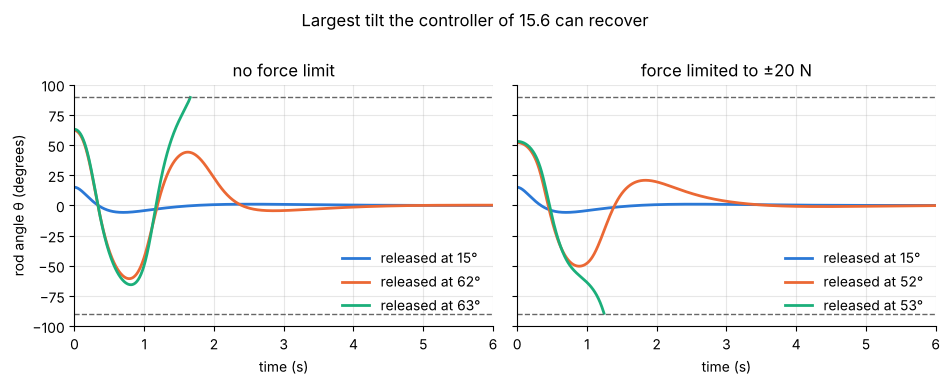

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.8), sharey=True)
for ax, F_max, name in zip(axes, (np.inf, 20.0), ("no force limit", "force limited to ±20 N")):
    low, high = limits[F_max]
    for tilt in (15, np.floor(low), np.ceil(high)):
        _, time, y, _ = simulate(tilt, F_max)
        ax.plot(time, np.degrees(y[1]), label=f"released at {tilt:.0f}°")
    for horizontal in (-90, 90):                          # the rod is lying flat: the run is stopped
        ax.axhline(horizontal, color="0.4", lw=1, ls="--")
    ax.set(xlabel="time (s)", xlim=(0, 6), ylim=(-100, 100), title=name)
    ax.legend(frameon=False, loc="lower right")
axes[0].set_ylabel("rod angle θ (degrees)")
fig.suptitle("Largest tilt the controller of 15.6 can recover", y=1.0)
fig.tight_layout()

**Answer.** With unlimited force the controller recovers the pendulum from initial tilts up to
about 62.7°. With the force limited to $\pm20$ N the largest tilt is about 52.4°, below the
static bound $\arctan\{F_{max}/[(M+m)g]\} = 59.5°$. By symmetry the same limits hold for a tilt to
the left. Even without a force limit the controller fails well before 90°: its gains were
designed on the linear model, and the leverage of the cart on the rod is proportional to
$\cos\theta$, which vanishes as the rod approaches the horizontal. Near either limit the rod
first swings far over to the other side, and the cart travels more than 3.5 m, so in practice
the track length would limit the tilt first.